# Clasification 

Customers about to leave and wanna know the probability of the risk to leave of each of them

## Binnary Classification - Data Prep



In [1]:
import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt 


In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

!wget $data -O data-week-3.csv

--2026-10-12 19:20:27--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 977501 (955K) [text/plain]
Saving to: ‘data-week-3.csv’

data-week-3.csv     100%[===================>] 954.59K  --.-KB/s    in 0.009s  

2026-10-12 19:20:27 (109 MB/s) - ‘data-week-3.csv’ saved [977501/977501]



In [3]:
#PATH = 'Lesson3-Classification'
df = pd.read_csv('data-week-3.csv')
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [6]:
df.dtypes


customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges            str
churn                   str
dtype: object

In [7]:
# pd.to_numeric(df.totalcharges)


In [8]:
tc = pd.to_numeric(df.totalcharges, errors='coerce')


In [9]:
tc.isnull().sum()

np.int64(11)

In [10]:
df[tc.isnull()][['customerid', 'totalcharges']]

,customerid,totalcharges
488,4472-LVYGI,
753,3115-CZMZD,
936,5709-LVOEQ,
1082,4367-NUYAO,
1340,1371-DWPAZ,
3331,7644-OMVMY,
3826,3213-VVOLG,
4380,2520-SGTTA,
5218,2923-ARZLG,
6670,4075-WKNIU,


In [11]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

In [12]:
df[tc.isnull()][['customerid', 'totalcharges']]

,customerid,totalcharges
488,4472-LVYGI,0.0
753,3115-CZMZD,0.0
936,5709-LVOEQ,0.0
1082,4367-NUYAO,0.0
1340,1371-DWPAZ,0.0
3331,7644-OMVMY,0.0
3826,3213-VVOLG,0.0
4380,2520-SGTTA,0.0
5218,2923-ARZLG,0.0
6670,4075-WKNIU,0.0


# Encoding the Variable

In [13]:
df.churn.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: churn, dtype: str

We need numbers for classification, this produces a boolean series casting them into integers

In [14]:
df.churn = df.churn.str.lower().eq('yes').astype(int)

In [15]:
df.churn.head()


0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

# 03 - Validation

We need to split the dataset from training to validation set  60% - training 20% validation and 20% testing 

This is section says how to isolates out target inside the dataste wich are the churn values

In [16]:
from sklearn.model_selection import train_test_split

Making aside 20 percent of the data

In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [18]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [19]:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

In [20]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

Here we need to isolate the target we are extracting it from each dataframe as numpy array

In [21]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [22]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

# 04 eda

In [23]:
df_full_train = df_full_train.reset_index(drop=True)

In [24]:
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [25]:
df_full_train.churn.value_counts(normalize=True).rename_axis(None).rename('churn')

0    0.730032
1    0.269968
Name: churn, dtype: float64

In [26]:
df_full_train.churn.mean()

np.float64(0.26996805111821087)

In [27]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

In [28]:
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [29]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

The EDA for this project consisted of:

Checking missing values
Looking at the distribution of the target variable (churn)
Looking at numerical and categorical variables
Functions and methods:

df.isnull().sum() - returns the number of null values in the dataframe.
df.x.value_counts() returns the number of values for each category in x series. The normalize=True argument retrieves the percentage of each category. In this project, the mean of churn is equal to the churn rate obtained with the value_counts method.
round(x, y) - round an x number with y decimal places
df[x].nunique() - returns the number of unique values in x series

El error estaba en la celda que convertía churn a números:

df.churn = (df.churn == 'yes').astype(int)
 
Los valores originales eran "Yes" y "No" (con mayúscula), así que la comparación con "yes" nunca coincidía. Por eso todos quedaban como 0.

La cambié para ignorar mayúsculas y minúsculas:

df.churn = df.churn.str.lower().eq('yes').astype(int)



# 05 Risk

The reference point is the global churn rate - the churn rate we computed in the EDA unit:

In [31]:
global_churn = df_full_train.churn.mean()
print (global_churn)

0.26996805111821087


In [36]:
# We can look at churn rate within different groups. For example, we can use gender
churn_female = df_full_train[df_full_train.gender == 'Female'].churn.mean()
churn_female

np.float64(0.27682403433476394)

In [37]:
churn_male = df_full_train[df_full_train.gender == 'Male'].churn.mean()
churn_male

np.float64(0.2632135306553911)

In [38]:
global_churn = df_full_train.churn.mean()
global_churn

np.float64(0.26996805111821087)

In [39]:
global_churn - churn_female

np.float64(-0.006855983216553063)

In [40]:
global_churn - churn_male

np.float64(0.006754520462819769)

In [41]:
# We can also use the 'partner' group 
df_full_train.partner.value_counts()

partner
No     2932
Yes    2702
Name: count, dtype: int64

In [43]:
churn_partner = df_full_train[df_full_train.partner == 'Yes'].churn.mean()
churn_partner

np.float64(0.20503330866025166)

In [44]:
# Oh wow, the difference is huge! 6% of the dataset.
global_churn - churn_partner

np.float64(0.06493474245795922)

In [45]:
churn_no_partner = df_full_train[df_full_train.partner == 'No'].churn.mean()
churn_no_partner

np.float64(0.3298090040927694)

In [46]:
# 6%, still quite a big difference in percentage. 
global_churn - churn_no_partner

np.float64(-0.05984095297455855)

# Risk Ratio

In [47]:
churn_no_partner / global_churn

np.float64(1.2216593879412643)

In [48]:
churn_partner / global_churn

np.float64(0.7594724924338315)

In [49]:
from IPython.display import display

In [50]:
for c in categorical:
    # Printing category via for loop aka point 1
    print(c)
    
    # We create a new dataframe, including the churn rate and the churn count
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    
    # Then, we create a new column 'diff' and measure the churn rate difference
    df_group['diff'] = df_group['mean'] - global_churn
    
    #Lastly, we create another new column 'risk' and measure the risk ratio. 
    df_group['risk'] = df_group['mean'] / global_churn
    
    #Formatting things
    display(df_group)
    print()
    print()

gender


,mean,count,diff,risk
gender,,,,
Female,0.276824,2796,0.006856,1.025396
Male,0.263214,2838,-0.006755,0.974980




seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208




partner


...

,mean,count,diff,risk
contract,,,,
Month-to-month,0.431701,3104,0.161733,1.599082
One year,0.120573,1186,-0.149395,0.446621
Two year,0.028274,1344,-0.241694,0.104730




paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
No,0.172071,2313,-0.097897,0.637375
Yes,0.338151,3321,0.068183,1.252560




paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
Bank transfer (automatic),0.168171,1219,-0.101797,0.622928
Credit card (automatic),0.164339,1217,-0.105630,0.608733
Electronic check,0.455890,1893,0.185922,1.688682
Mailed check,0.193870,1305,-0.076098,0.718121


# 3.6 Feature importance: Mutual information

In [51]:
from sklearn.metrics import mutual_info_score

In [52]:
# The value can tell us that there is some relation between the 'churn' variable and the 'contract' variable
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

In [53]:
# However, this values shows us that there is little to no relation at all. 
mutual_info_score(df_full_train.gender, df_full_train.churn)

0.0001174846211139946

In [54]:
mutual_info_score(df_full_train.partner, df_full_train.churn)

0.009967689095399745

In [55]:
# MI scores between 'churn' column and other 'groups'
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

In [56]:
# .apply() allows us to apply a function to the dataframe/dataset itself
# in this case, we apply the previous function above to get the MI scores. 
mi = df_full_train[categorical].apply(mutual_info_churn_score)

mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

In [57]:
# We are using tenure for this case
df_full_train.tenure.max()

np.int64(72)

In [58]:
# These are the correlations between the numerical variables and the churn variable.
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

In [59]:
# We will be exploring tenure first.
df_full_train[df_full_train.tenure <= 2].churn.mean()

np.float64(0.5953420669577875)

In [60]:
df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean()

np.float64(0.3994413407821229)

In [61]:
df_full_train[df_full_train.tenure > 12].churn.mean()

np.float64(0.17634908339788277)

In [62]:
df_full_train[df_full_train.monthlycharges <= 20].churn.mean()

np.float64(0.08795411089866156)

In [63]:
df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean()

np.float64(0.18340943683409436)

In [64]:
df_full_train[df_full_train.monthlycharges > 50].churn.mean()

np.float64(0.32499341585462205)

In [65]:
from sklearn.feature_extraction import DictVectorizer

In [66]:
# Here's some code to make more sense of the process first. 
# We have categorical variables like male & female in gender, month-to-month, one_year & two_year in contract.
df_train[['gender','contract']].iloc[:10]

,gender,contract
0,Female,Two year
1,Male,Month-to-month
2,Female,Month-to-month
3,Female,Month-to-month
4,Female,Two year
5,Male,Month-to-month
6,Male,Month-to-month
7,Female,Month-to-month
8,Female,Two year
9,Female,Month-to-month


In [67]:
df_train[['gender','contract']].iloc[:10].to_dict()

{'gender': {0: 'Female',
  1: 'Male',
  2: 'Female',
  3: 'Female',
  4: 'Female',
  5: 'Male',
  6: 'Male',
  7: 'Female',
  8: 'Female',
  9: 'Female'},
 'contract': {0: 'Two year',
  1: 'Month-to-month',
  2: 'Month-to-month',
  3: 'Month-to-month',
  4: 'Two year',
  5: 'Month-to-month',
  6: 'Month-to-month',
  7: 'Month-to-month',
  8: 'Two year',
  9: 'Month-to-month'}}

In [68]:
# This is how we would have to save it, with the orient 'records'.
test = df_train[['gender','contract']].iloc[:100].to_dict(orient = 'records')

# Feel free to delete the # to see the dictionary in its proper form.
# test

In [69]:
# Fitting and transforming the data
dv = DictVectorizer(sparse=False)
test = dv.fit_transform(test)

In [70]:
test

array([[0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 0., 1.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 1., 0., 0., 1.],
       [0., 0., 1., 0., 1.],
       [1., 0., 0., 0., 1.],
       [0., 1., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [0., 0., 1., 0., 1.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 1., 0., 1., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 0., 1.],
       [0., 1., 0., 1., 0.],
       [0., 1., 0., 1., 0.],
       [1., 0.

In [72]:
# The features are in order, aka month-to-month is the first column, one_year is the second column, etc.
dv.get_feature_names_out()

array(['contract=Month-to-month', 'contract=One year',
       'contract=Two year', 'gender=Female', 'gender=Male'], dtype=object)

In [73]:
# Let's add in a numerical column to see what happens when we vectorize it
test_2 = df_train[['gender','contract', 'tenure']].iloc[:100].to_dict(orient = 'records')

In [74]:
test_2 = dv.fit_transform(test_2)

In [75]:
train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [76]:
test_3 = df_train[['gender','contract']].iloc[:100]
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(handle_unknown = 'ignore')
test_3 = enc.fit_transform(test_3)

In [77]:
test_3_display = pd.DataFrame(test_3.toarray())
test_3_display

,0,1,2,3,4
0,1.0,0.0,0.0,0.0,1.0
1,0.0,1.0,1.0,0.0,0.0
2,1.0,0.0,1.0,0.0,0.0
3,1.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...
95,0.0,1.0,0.0,1.0,0.0
96,1.0,0.0,1.0,0.0,0.0
97,0.0,1.0,1.0,0.0,0.0
98,0.0,1.0,0.0,1.0,0.0


# Logistic Regression


In [78]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [79]:
# linspace() gives 51 evenly spaced out numbers from the range (-7, 7).
z = np.linspace(-7, 7, 51)

In [80]:
# Very extreme values usually lie towards 0 or 1, depending on the positivity/negativity of the number
# You can tell from -10 onwards whereby the value, when rounded to 5 decimal places, leads to 0.
# Same goes for 10 onwards, whereby the value leads to 1.

values = [-1000, -100, -50, -10, -7.5, -5, -3, -1, 0, 1, 3, 5, 7.5, 10, 50, 100, 1000]

for value in values:
    print(round(sigmoid(value),5))

0.0
0.0
0.0
5e-05
0.00055
0.00669
0.04743
0.26894
0.5
0.73106
0.95257
0.99331
0.99945
0.99995
1.0
1.0
1.0


/tmp/ipykernel_3043/3196251242.py:2: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


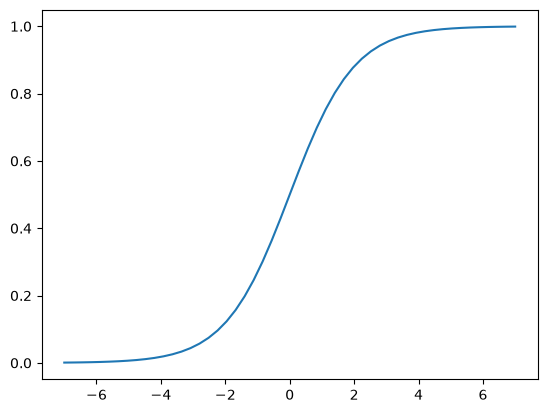

In [81]:
plt.plot(z, sigmoid(z))

In [82]:
def linear_regression(xi):
    result = w0
    
    for j in range(len(w)):
        result = result + xi[j] * w[j]
        
    return result

In [83]:
# Logistic Regressions works just like linear regression WITH the sigmoid function applied to the scores.
def logistic_regression(xi):
    score = w0
    
    for j in range(len(w)):
        score = score + xi[j] * w[j]
        
    result = sigmoid(score)
    return result

In [84]:
from sklearn.linear_model import LogisticRegression

In [85]:
model = LogisticRegression(solver='lbfgs')

# solver='lbfgs' is the default solver in newer version of sklearn
# for older versions, you need to specify it explicitly
model.fit(X_train, y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [86]:
# Bias 
model.intercept_[0]

np.float64(-0.10913176644533581)

In [87]:
# Weights
model.coef_[0].round(3)

array([ 0.474, -0.175, -0.407, -0.03 , -0.078,  0.063, -0.089, -0.081,
       -0.034, -0.073, -0.335,  0.316, -0.089,  0.004, -0.258,  0.141,
        0.009,  0.063, -0.089, -0.081,  0.265, -0.089, -0.284, -0.231,
        0.123, -0.166,  0.058, -0.087, -0.032,  0.07 , -0.059,  0.141,
       -0.249,  0.215, -0.12 , -0.089,  0.102, -0.071, -0.089,  0.052,
        0.213, -0.089, -0.232, -0.071,  0.   ])

In [88]:
# Hard predictions
model.predict(X_train) 

array([0, 1, 1, ..., 1, 0, 1], shape=(4225,))

In [89]:
# Soft predictions
# predict_proba will give us the probability of churn being 0, and churn being 1.
# The probabilities in each element of the array add up to 1, like [0.98945691, 0.01054309] for example
y_pred = model.predict_proba(X_val)
y_pred

array([[0.99099851, 0.00900149],
       [0.79590966, 0.20409034],
       [0.78827495, 0.21172505],
       ...,
       [0.86364921, 0.13635079],
       [0.20057621, 0.79942379],
       [0.16291404, 0.83708596]], shape=(1409, 2))

In [90]:
# We only want the probability of churn being 1. 
y_pred[:, 1]

array([0.00900149, 0.20409034, 0.21172505, ..., 0.13635079, 0.79942379,
       0.83708596], shape=(1409,))

In [91]:
y_pred = model.predict_proba(X_val)[:, 1]

In [92]:
# Ultimately, we have decided that 0.5 will be the threshold whereby we consider churn to be 1. 
churn_decision = (y_pred >= 0.5)
churn_decision

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [93]:
# Calculating the accuracy of the model itself. 0.803, not bad! 
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [94]:
# Creation of prediction dataframe

df_pred = pd.DataFrame()

# Probability of the customer churning
df_pred['probability'] = y_pred

# Convert into 0 or 1, basically y_pred in a typical situation
df_pred['prediction'] = churn_decision.astype(int)

# y_val data being converted into a column 
df_pred['actual'] = y_val

In [95]:
df_pred['correct'] = df_pred.prediction == df_pred.actual

In [96]:
df_pred.correct.mean()

np.float64(0.8034066713981547)

In [97]:
churn_decision.astype(int)


array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [98]:
a = [1, 2, 3, 4]
b = 'abcd'

In [99]:
# Demonstrating how dict(zip()) works
dict(zip(a, b))

{1: 'a', 2: 'b', 3: 'c', 4: 'd'}

In [101]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=Month-to-month': np.float64(0.474),
 'contract=One year': np.float64(-0.175),
 'contract=Two year': np.float64(-0.407),
 'dependents=No': np.float64(-0.03),
 'dependents=Yes': np.float64(-0.078),
 'deviceprotection=No': np.float64(0.063),
 'deviceprotection=No internet service': np.float64(-0.089),
 'deviceprotection=Yes': np.float64(-0.081),
 'gender=Female': np.float64(-0.034),
 'gender=Male': np.float64(-0.073),
 'internetservice=DSL': np.float64(-0.335),
 'internetservice=Fiber optic': np.float64(0.316),
 'internetservice=No': np.float64(-0.089),
 'monthlycharges': np.float64(0.004),
 'multiplelines=No': np.float64(-0.258),
 'multiplelines=No phone service': np.float64(0.141),
 'multiplelines=Yes': np.float64(0.009),
 'onlinebackup=No': np.float64(0.063),
 'onlinebackup=No internet service': np.float64(-0.089),
 'onlinebackup=Yes': np.float64(-0.081),
 'onlinesecurity=No': np.float64(0.265),
 'onlinesecurity=No internet service': np.float64(-0.089),
 'onlinesecurity=Yes'

In [102]:
# We're going to be working with a smaller model instead, with fewer features 
small = ['contract', 'tenure', 'monthlycharges']

In [103]:
df_train[small].iloc[:10].to_dict(orient='records')

[{'contract': 'Two year', 'tenure': 72, 'monthlycharges': 115.5},
 {'contract': 'Month-to-month', 'tenure': 10, 'monthlycharges': 95.25},
 {'contract': 'Month-to-month', 'tenure': 5, 'monthlycharges': 75.55},
 {'contract': 'Month-to-month', 'tenure': 5, 'monthlycharges': 80.85},
 {'contract': 'Two year', 'tenure': 18, 'monthlycharges': 20.1},
 {'contract': 'Month-to-month', 'tenure': 4, 'monthlycharges': 30.5},
 {'contract': 'Month-to-month', 'tenure': 1, 'monthlycharges': 75.1},
 {'contract': 'Month-to-month', 'tenure': 1, 'monthlycharges': 70.3},
 {'contract': 'Two year', 'tenure': 72, 'monthlycharges': 19.75},
 {'contract': 'Month-to-month', 'tenure': 6, 'monthlycharges': 109.9}]

In [104]:
dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

In [105]:
# Fitting to DictVectorizer
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

In [106]:
dv_small.get_feature_names_out()

array(['contract=Month-to-month', 'contract=One year',
       'contract=Two year', 'monthlycharges', 'tenure'], dtype=object)

In [107]:
X_train_small = dv_small.transform(dicts_train_small)

In [108]:
model_small = LogisticRegression(solver='lbfgs')
model_small.fit(X_train_small, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [109]:
# w0 
w0 = model_small.intercept_[0]
w0

np.float64(-2.477957595284362)

In [111]:
# w1 to w5 
w = model_small.coef_[0]
w.round(3)

array([ 0.971, -0.024, -0.948,  0.027, -0.036])

In [115]:
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

{'contract=Month-to-month': np.float64(0.971),
 'contract=One year': np.float64(-0.024),
 'contract=Two year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

In [116]:
# Remember, logistic regression is just like linear regression just with the added Sigmoid function.

-2.47 + (-0.949) + 30 * 0.027 + 24 * (-0.036)

-3.473

In [117]:
sigmoid(_)

np.float64(0.030090303318277657)

In [118]:
# Preparation of the data to be vectorized 
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

In [119]:
dv = DictVectorizer(sparse=False)

# Splitting of the data to X and y 
X_full_train = dv.fit_transform(dicts_full_train)

In [120]:
y_full_train = df_full_train.churn.values

In [121]:
# Fitting into model
model = LogisticRegression(solver='lbfgs')
model.fit(X_full_train, y_full_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [122]:
# Preparation of test data to be vectorized 
dicts_test = df_test[categorical + numerical].to_dict(orient='records')

In [123]:
X_test = dv.transform(dicts_test)

In [124]:
# Predictions from X_test
y_pred = model.predict_proba(X_test)[:, 1]

In [125]:
churn_decision = (y_pred >= 0.5)

In [126]:
(churn_decision == y_test).mean()

np.float64(0.8147622427253371)

In [127]:
# Getting the info of the customer itself, so that we can calculate the probability.
customer = dicts_test[-1]
customer

{'gender': 'Female',
 'seniorcitizen': 0,
 'partner': 'Yes',
 'dependents': 'Yes',
 'phoneservice': 'Yes',
 'multiplelines': 'Yes',
 'internetservice': 'Fiber optic',
 'onlinesecurity': 'Yes',
 'onlinebackup': 'No',
 'deviceprotection': 'Yes',
 'techsupport': 'No',
 'streamingtv': 'Yes',
 'streamingmovies': 'Yes',
 'contract': 'Month-to-month',
 'paperlessbilling': 'Yes',
 'paymentmethod': 'Electronic check',
 'tenure': 17,
 'monthlycharges': 104.2,
 'totalcharges': 1743.5}

In [128]:
X_small = dv.transform([customer])

In [129]:

model.predict_proba(X_small)[0, 1]

np.float64(0.6546648535787962)

In [130]:
y_test[-1]

np.int64(1)

In [134]:
df['industry'].value_counts(dropna=False)

KeyError: 'industry'